In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

processed_path = Path("../data/processed")

# Final explainable risk output
risk_data = pd.read_csv(
    processed_path / "final_risk_scores_explainable.csv"
)

# Customer information
customers = pd.read_csv(
    "../data/raw/customers.csv"
)

# Phase 12 calibrated/uncertainty output
calibrated_path = (
    processed_path / "calibrated_credit_risk.csv"
)

print("Risk data:", risk_data.shape)
print("Customer data:", customers.shape)

print("\nRisk columns:")
print(risk_data.columns.tolist())

Risk data: (10000, 20)
Customer data: (10000, 13)

Risk columns:
['customer_id', 'credit_risk_probability', 'credit_risk_score', 'temporal_risk_probability', 'temporal_risk_score', 'avg_fraud_probability', 'max_fraud_probability', 'avg_anomaly_score', 'max_anomaly_score', 'avg_hybrid_fraud_score', 'max_hybrid_fraud_score', 'fraud_risk_score', 'graph_risk_score', 'financial_health_score', 'financial_health_risk_score', 'finrisk_score', 'risk_category', 'reason_1', 'reason_2', 'reason_3']


In [2]:
print("\nProcessed files containing calibration/uncertainty:")

for file in processed_path.iterdir():
    if any(
        word in file.name.lower()
        for word in [
            "calibr",
            "uncertain",
            "confidence",
            "review"
        ]
    ):
        print(file.name)


Processed files containing calibration/uncertainty:
calibration_comparison.csv
final_risk_scores_uncertainty_aware.csv


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

processed_path = Path("../data/processed")
figures_path = Path("../reports/figures")

risk_data = pd.read_csv(
    processed_path / "final_risk_scores_uncertainty_aware.csv"
)

print("Dataset shape:", risk_data.shape)

print("\nColumns:")
for col in risk_data.columns:
    print("-", col)

print("\nFirst 5 records:")
display(risk_data.head())

Dataset shape: (10000, 25)

Columns:
- customer_id
- credit_risk_probability
- credit_risk_score
- temporal_risk_probability
- temporal_risk_score
- avg_fraud_probability
- max_fraud_probability
- avg_anomaly_score
- max_anomaly_score
- avg_hybrid_fraud_score
- max_hybrid_fraud_score
- fraud_risk_score
- graph_risk_score
- financial_health_score
- financial_health_risk_score
- finrisk_score
- risk_category
- reason_1
- reason_2
- reason_3
- calibrated_credit_probability
- credit_uncertainty_score
- credit_confidence_score
- credit_uncertainty_category
- human_review_required

First 5 records:


,customer_id,credit_risk_probability,credit_risk_score,temporal_risk_probability,temporal_risk_score,avg_fraud_probability,max_fraud_probability,avg_anomaly_score,max_anomaly_score,avg_hybrid_fraud_score,...,finrisk_score,risk_category,reason_1,reason_2,reason_3,calibrated_credit_probability,credit_uncertainty_score,credit_confidence_score,credit_uncertainty_category,human_review_required
0,100001,0.393545,39.354540,0.351935,35.193510,0.262764,0.783083,0.185125,0.816251,0.239472,...,38.242348,Moderate,employment_years increased risk,savings_to_loan reduced risk,total_spending reduced risk,0.367032,0.734065,0.265935,High Uncertainty,True
1,100002,0.665469,66.546906,0.315314,31.531355,0.313527,0.803767,0.221139,0.709282,0.285810,...,46.359409,Moderate,employment_years increased risk,savings increased risk,payment_to_income increased risk,0.549241,0.901517,0.098483,High Uncertainty,True
2,100003,0.515152,51.515220,0.410704,41.070427,0.476873,0.783061,0.261322,0.502814,0.412207,...,45.627977,Moderate,credit_score increased risk,debt_to_income reduced risk,savings reduced risk,0.451192,0.902384,0.097616,High Uncertainty,True
3,100004,0.411317,41.131725,0.357690,35.768967,0.266366,0.797005,0.227899,0.488348,0.254826,...,40.674674,Moderate,debt_to_income reduced risk,total_spending increased risk,annual_income increased risk,0.364358,0.728716,0.271284,High Uncertainty,True
4,100005,0.573910,57.391030,0.325702,32.570225,0.295973,0.812917,0.247687,0.494577,0.281487,...,43.396794,Moderate,debt_to_income increased risk,existing_debt increased risk,savings reduced risk,0.434674,0.869349,0.130651,High Uncertainty,True


In [4]:
print("Risk Category Distribution:")
display(
    risk_data["risk_category"]
    .value_counts(dropna=False)
)

print("\nFinRisk Score Statistics:")
display(
    risk_data["finrisk_score"].describe()
)

Risk Category Distribution:


risk_category
Moderate    9284
High         594
Low          122
Name: count, dtype: int64


FinRisk Score Statistics:


count    10000.000000
mean        36.727223
std          7.163890
min         18.663046
25%         31.453581
50%         35.321626
75%         41.076361
max         65.841460
Name: finrisk_score, dtype: float64

In [5]:
uncertainty_columns = [
    col for col in risk_data.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "uncertainty",
            "confidence",
            "calibrated",
            "review"
        ]
    )
]

print("Detected uncertainty-related columns:")

for col in uncertainty_columns:
    print("-", col)

Detected uncertainty-related columns:
- calibrated_credit_probability
- credit_uncertainty_score
- credit_confidence_score
- credit_uncertainty_category
- human_review_required


In [6]:
display(
    risk_data[
        ["customer_id", "finrisk_score", "risk_category"]
        + uncertainty_columns
    ].head(10)
)

,customer_id,finrisk_score,risk_category,calibrated_credit_probability,credit_uncertainty_score,credit_confidence_score,credit_uncertainty_category,human_review_required
0,100001,38.242348,Moderate,0.367032,0.734065,0.265935,High Uncertainty,True
1,100002,46.359409,Moderate,0.549241,0.901517,0.098483,High Uncertainty,True
2,100003,45.627977,Moderate,0.451192,0.902384,0.097616,High Uncertainty,True
3,100004,40.674674,Moderate,0.364358,0.728716,0.271284,High Uncertainty,True
4,100005,43.396794,Moderate,0.434674,0.869349,0.130651,High Uncertainty,True
5,100006,35.141749,Moderate,0.287274,0.574548,0.425452,High Uncertainty,True
6,100007,41.617257,Moderate,0.361521,0.723042,0.276958,High Uncertainty,True
7,100008,34.773961,Moderate,0.312719,0.625437,0.374563,High Uncertainty,True
8,100009,43.976036,Moderate,0.436347,0.872693,0.127307,High Uncertainty,True
9,100010,40.938697,Moderate,0.427337,0.854675,0.145325,High Uncertainty,True


In [7]:
print("Uncertainty categories:")
display(
    risk_data["credit_uncertainty_category"]
    .value_counts(dropna=False)
)

print("\nHuman review distribution:")
display(
    risk_data["human_review_required"]
    .value_counts(dropna=False)
)

print("\nRisk category distribution:")
display(
    risk_data["risk_category"]
    .value_counts(dropna=False)
)

Uncertainty categories:


credit_uncertainty_category
High Uncertainty        8193
Moderate Uncertainty    1807
Name: count, dtype: int64


Human review distribution:


human_review_required
True     8193
False    1807
Name: count, dtype: int64


Risk category distribution:


risk_category
Moderate    9284
High         594
Low          122
Name: count, dtype: int64

In [8]:
def decision_engine(row):

    risk = row["finrisk_score"]
    uncertainty = row["credit_uncertainty_score"]
    human_review = row["human_review_required"]

    # High uncertainty always goes to human review
    if human_review or uncertainty >= 0.40:
        return "Human Review"

    # High overall risk
    if risk >= 75:
        return "Reject"

    # Moderate risk
    elif risk >= 50:
        return "Enhanced Review"

    # Low risk
    else:
        return "Approve"


risk_data["decision"] = risk_data.apply(
    decision_engine,
    axis=1
)

print("Decision distribution:")
display(
    risk_data["decision"].value_counts()
)

Decision distribution:


decision
Human Review    8193
Approve         1807
Name: count, dtype: int64

In [9]:
def generate_decision_reason(row):

    reasons = []

    if row["credit_risk_score"] >= 50:
        reasons.append("Elevated credit risk")

    if row["temporal_risk_score"] >= 50:
        reasons.append("Elevated temporal risk")

    if row["fraud_risk_score"] >= 50:
        reasons.append("Elevated fraud risk")

    if row["graph_risk_score"] >= 50:
        reasons.append("Elevated network/graph risk")

    if row["financial_health_risk_score"] >= 50:
        reasons.append("Weak financial health")

    if row["human_review_required"]:
        reasons.append("High model uncertainty")

    if not reasons:
        reasons.append("No major risk indicators detected")

    return "; ".join(reasons[:3])


risk_data["decision_reason"] = risk_data.apply(
    generate_decision_reason,
    axis=1
)

display(
    risk_data[
        [
            "customer_id",
            "finrisk_score",
            "risk_category",
            "decision",
            "decision_reason"
        ]
    ].head(10)
)

,customer_id,finrisk_score,risk_category,decision,decision_reason
0,100001,38.242348,Moderate,Human Review,Elevated fraud risk; High model uncertainty
1,100002,46.359409,Moderate,Human Review,Elevated credit risk; High model uncertainty
2,100003,45.627977,Moderate,Human Review,Elevated credit risk; Elevated fraud risk; Hig...
3,100004,40.674674,Moderate,Human Review,High model uncertainty
4,100005,43.396794,Moderate,Human Review,Elevated credit risk; Elevated fraud risk; Hig...
5,100006,35.141749,Moderate,Human Review,Elevated fraud risk; High model uncertainty
6,100007,41.617257,Moderate,Human Review,Elevated fraud risk; Elevated network/graph ri...
7,100008,34.773961,Moderate,Human Review,Elevated fraud risk; High model uncertainty
8,100009,43.976036,Moderate,Human Review,Elevated credit risk; Elevated fraud risk; Hig...
9,100010,40.938697,Moderate,Human Review,High model uncertainty


In [10]:
def recommended_action(row):

    decision = row["decision"]

    if decision == "Approve":
        return "Approve with standard monitoring"

    elif decision == "Enhanced Review":
        return "Perform enhanced financial and credit review"

    elif decision == "Human Review":
        return "Escalate to human analyst for manual assessment"

    elif decision == "Reject":
        return "Reject or apply strict lending controls"

    return "Manual assessment required"


risk_data["recommended_action"] = risk_data.apply(
    recommended_action,
    axis=1
)

display(
    risk_data[
        [
            "customer_id",
            "decision",
            "decision_reason",
            "recommended_action"
        ]
    ].head(10)
)

,customer_id,decision,decision_reason,recommended_action
0,100001,Human Review,Elevated fraud risk; High model uncertainty,Escalate to human analyst for manual assessment
1,100002,Human Review,Elevated credit risk; High model uncertainty,Escalate to human analyst for manual assessment
2,100003,Human Review,Elevated credit risk; Elevated fraud risk; Hig...,Escalate to human analyst for manual assessment
3,100004,Human Review,High model uncertainty,Escalate to human analyst for manual assessment
4,100005,Human Review,Elevated credit risk; Elevated fraud risk; Hig...,Escalate to human analyst for manual assessment
5,100006,Human Review,Elevated fraud risk; High model uncertainty,Escalate to human analyst for manual assessment
6,100007,Human Review,Elevated fraud risk; Elevated network/graph ri...,Escalate to human analyst for manual assessment
7,100008,Human Review,Elevated fraud risk; High model uncertainty,Escalate to human analyst for manual assessment
8,100009,Human Review,Elevated credit risk; Elevated fraud risk; Hig...,Escalate to human analyst for manual assessment
9,100010,Human Review,High model uncertainty,Escalate to human analyst for manual assessment


In [11]:
risk_data["decision_confidence"] = (
    risk_data["credit_confidence_score"]
)

risk_data[
    [
        "customer_id",
        "decision",
        "decision_confidence",
        "credit_uncertainty_category"
    ]
].head(10)

,customer_id,decision,decision_confidence,credit_uncertainty_category
0,100001,Human Review,0.265935,High Uncertainty
1,100002,Human Review,0.098483,High Uncertainty
2,100003,Human Review,0.097616,High Uncertainty
3,100004,Human Review,0.271284,High Uncertainty
4,100005,Human Review,0.130651,High Uncertainty
5,100006,Human Review,0.425452,High Uncertainty
6,100007,Human Review,0.276958,High Uncertainty
7,100008,Human Review,0.374563,High Uncertainty
8,100009,Human Review,0.127307,High Uncertainty
9,100010,Human Review,0.145325,High Uncertainty


In [12]:
decision_summary = (
    risk_data
    .groupby("decision")
    .agg(
        customer_count=("customer_id", "count"),
        average_finrisk_score=("finrisk_score", "mean"),
        average_confidence=("decision_confidence", "mean"),
        average_uncertainty=("credit_uncertainty_score", "mean")
    )
    .reset_index()
)

display(decision_summary)

,decision,customer_count,average_finrisk_score,average_confidence,average_uncertainty
0,Approve,1807,29.395863,0.643049,0.356951
1,Human Review,8193,38.344185,0.348727,0.651273


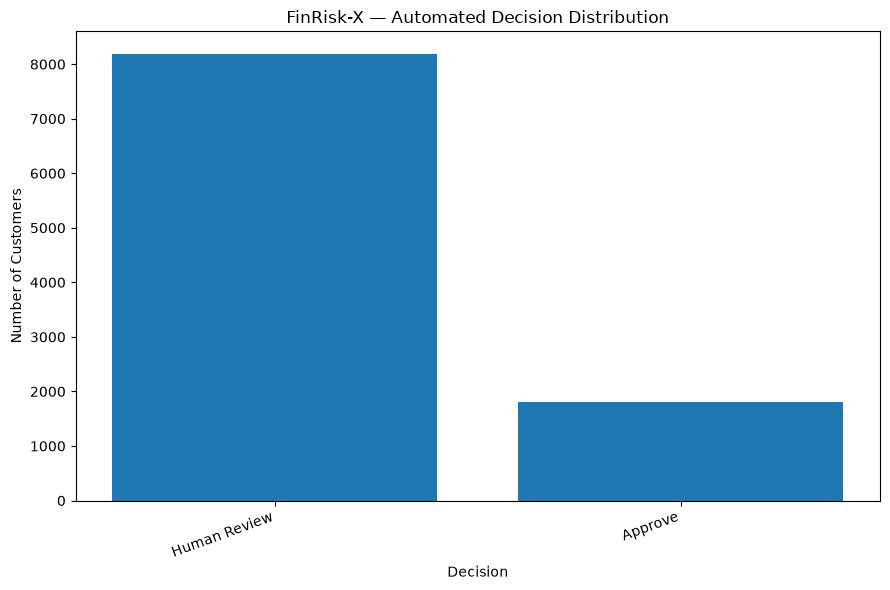

In [13]:
import matplotlib.pyplot as plt

decision_counts = (
    risk_data["decision"]
    .value_counts()
)

plt.figure(figsize=(9, 6))

plt.bar(
    decision_counts.index,
    decision_counts.values
)

plt.xlabel("Decision")
plt.ylabel("Number of Customers")
plt.title("FinRisk-X — Automated Decision Distribution")

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.savefig(
    figures_path / "decision_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

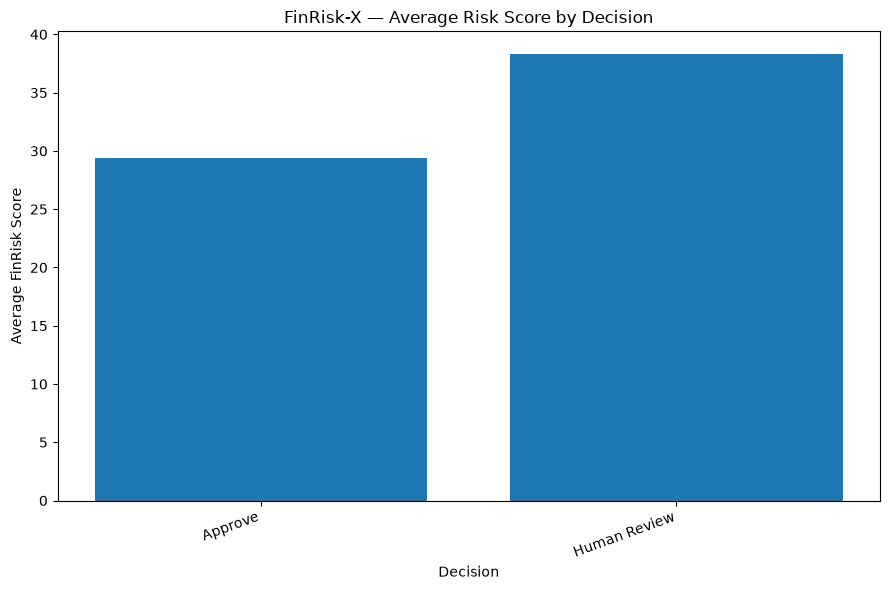

In [14]:
decision_risk = (
    risk_data
    .groupby("decision")["finrisk_score"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 6))

plt.bar(
    decision_risk.index,
    decision_risk.values
)

plt.xlabel("Decision")
plt.ylabel("Average FinRisk Score")
plt.title("FinRisk-X — Average Risk Score by Decision")

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.savefig(
    figures_path / "average_risk_by_decision.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [15]:
routing_data = pd.crosstab(
    risk_data["decision"],
    risk_data["credit_uncertainty_category"]
)

display(routing_data)

credit_uncertainty_category,High Uncertainty,Moderate Uncertainty
decision,,
Approve,0,1807
Human Review,8193,0


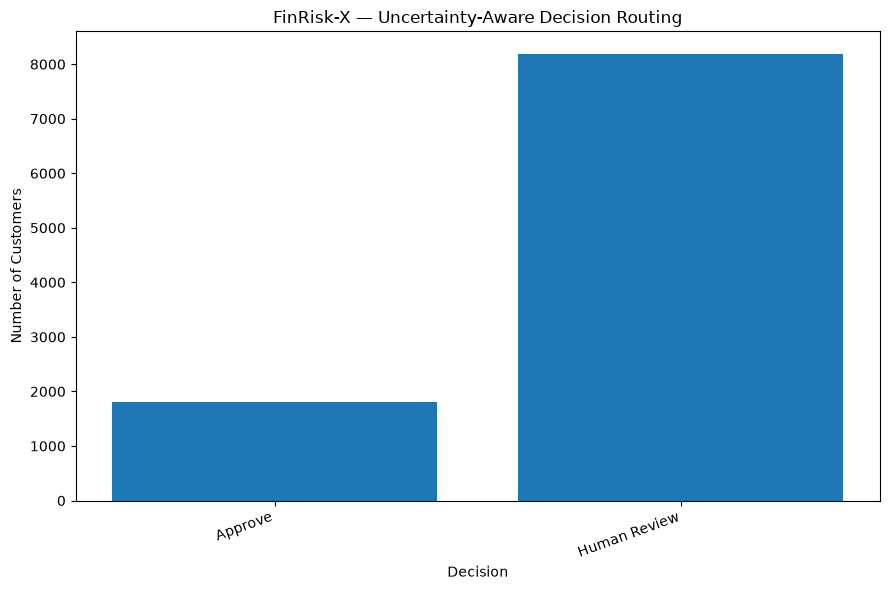

In [16]:
routing_plot = routing_data.sum(axis=1)

plt.figure(figsize=(9, 6))

plt.bar(
    routing_plot.index,
    routing_plot.values
)

plt.xlabel("Decision")
plt.ylabel("Number of Customers")
plt.title(
    "FinRisk-X — Uncertainty-Aware Decision Routing"
)

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.savefig(
    figures_path / "uncertainty_aware_decision_routing.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [17]:
decision_output_columns = [
    "customer_id",
    "credit_risk_probability",
    "credit_risk_score",
    "temporal_risk_probability",
    "temporal_risk_score",
    "avg_fraud_probability",
    "max_fraud_probability",
    "avg_anomaly_score",
    "max_anomaly_score",
    "avg_hybrid_fraud_score",
    "max_hybrid_fraud_score",
    "fraud_risk_score",
    "graph_risk_score",
    "financial_health_score",
    "financial_health_risk_score",
    "finrisk_score",
    "risk_category",
    "calibrated_credit_probability",
    "credit_uncertainty_score",
    "credit_confidence_score",
    "credit_uncertainty_category",
    "human_review_required",
    "decision",
    "decision_reason",
    "recommended_action",
    "decision_confidence"
]

decision_output = risk_data[
    decision_output_columns
].copy()

decision_output.to_csv(
    processed_path / "finrisk_decision_intelligence.csv",
    index=False
)

print(
    "Saved:",
    processed_path / "finrisk_decision_intelligence.csv"
)

print("Shape:", decision_output.shape)

Saved: ..\data\processed\finrisk_decision_intelligence.csv
Shape: (10000, 26)


In [18]:
expected_files = [
    processed_path / "finrisk_decision_intelligence.csv",
    figures_path / "decision_distribution.svg",
    figures_path / "average_risk_by_decision.svg",
    figures_path / "uncertainty_aware_decision_routing.svg"
]

print("Phase 14 Output Validation\n")

for file in expected_files:
    print(
        f"{file.name:<50}",
        "✓" if file.exists() else "✗"
    )

Phase 14 Output Validation

finrisk_decision_intelligence.csv                  ✓
decision_distribution.svg                          ✓
average_risk_by_decision.svg                       ✓
uncertainty_aware_decision_routing.svg             ✓
